In [19]:
# Week 4 Assignment: Statistics, Data Visualization & Exploratory Data Analysis
# Task 1: Statistical Analysis – Mean, Median & Mode
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('student_performance_dataset.csv')

df.shape

(1000, 12)

In [20]:
df.columns.tolist()

['StudentID',
 'Name',
 'Gender',
 'AttendanceRate',
 'StudyHoursPerWeek',
 'PreviousGrade',
 'ExtracurricularActivities',
 'ParentalSupport',
 'FinalGrade',
 'Study Hours',
 'Attendance (%)',
 'Online Classes Taken']

In [24]:
mean = df["FinalGrade"].mean()
median = df["FinalGrade"].median()
mode = df["FinalGrade"].mode()[0]

print("Mean:", mean)
print("Median:",median)
print("Mode:",mode)

Mean: 80.03020833333333
Median: 80.0
Mode: 72.0


# Explanation:

Mean:
The mean represents the average final grade of the students. The average FinalGrade is approximately 80.03.

Median:
The median is the middle value when the final grades are arranged in ascending order. The median is 80, meaning approximately half of the observations are below 80 and half are above 80.

Mode:
The mode is the most frequently occurring value. The mode of FinalGrade is 72, meaning 72 occurs more frequently than the other grade values.

In [25]:
# Task 2: Variance & Standard Deviation
variance = df["FinalGrade"].var()
sd = df["FinalGrade"].std()

print("Variance:", variance)
print("Standard Deviation:", sd)

Variance: 90.12943061348633
Standard Deviation: 9.493652121996378


# Explanation:

Variance measures how much the final grades vary around the mean. Standard deviation indicates the spread of final grades around the average.

A standard deviation of approximately 9.49 indicates that the students' final grades generally vary around the mean by about 9.49 grade points.

In [27]:
# Task 3: Correlation & Probability Basics
# Correlation

correlation = df["StudyHoursPerWeek"].corr(df["FinalGrade"])
print("Correlation:", correlation)

Correlation: 0.036393983776817546


# Explanation:

The correlation between StudyHoursPerWeek and FinalGrade is approximately 0.036. This indicates a very weak positive relationship between weekly study hours and final grades in this dataset.

In [28]:
# Probability

grades = df["FinalGrade"].dropna()

stu = (grades >= 70).sum()
tot_stu = len(grades)

prob = stu / tot_stu

print("Students with Final Grade >= 70:", stu)
print("Total Students:", tot_stu)
print("Probability:", prob)
print("Probability Percentage:", prob * 100, "%")

Students with Final Grade >= 70: 777
Total Students: 960
Probability: 0.809375
Probability Percentage: 80.9375 %


# Explanation:
Among the 960 students with available FinalGrade values, 777 students have a final grade of 70 or above.

Therefore, the probability of randomly selecting a student with a FinalGrade of at least 70 is approximately 0.8094, or 80.94%.

In [39]:
# Task 4: Outlier Detection

att = df["Attendance (%)"].dropna()

Q1 = att.quantile(0.25)
Q3 = att.quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\nLower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df["Attendance (%)"] < lower_bound) |
    (df["Attendance (%)"] > upper_bound)
]

print("\nPotential Outliers:")
print(outliers[["StudentID", "Name", "Attendance (%)"]])

Q1: 63.0
Q3: 89.0
IQR: 26.0

Lower Bound: 24.0
Upper Bound: 128.0

Potential Outliers:
     StudentID             Name  Attendance (%)
74      1470.0   Michelle Jones           200.0
125     3430.0     Jessica Lamb           200.0
148     5059.0  Michaela Powell           200.0
220     8484.0     Alicia Ortiz           200.0
251     3527.0   Michael Foster           200.0
321     3831.0  Jessica Jenkins           200.0
366     4659.0       Jill Kelly           200.0
380     6416.0  Raymond Murillo           200.0
672     8203.0   David Martinez           200.0
798     1378.0       Chad Colon           200.0


# Explanation:
The IQR method identified observations with Attendance (%) values of 200 as potential outliers because they exceed the calculated upper boundary of 128.

Since attendance percentage should normally fall within a 0–100% range, these values are also considered inconsistent values and should be corrected during data cleaning.

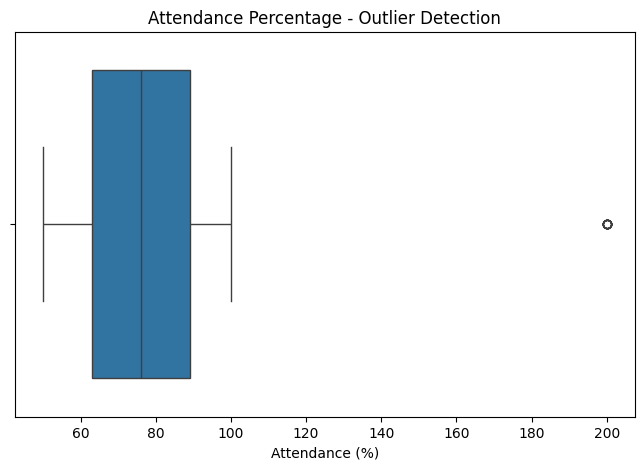

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Attendance (%)"])

plt.title("Attendance Percentage - Outlier Detection")
plt.xlabel("Attendance (%)")

plt.show()

# Box Plot Explanation:
The box plot displays the distribution of attendance percentages and highlights potential outliers. Most attendance values fall within the normal range, while the value around 200% appears as an isolated point beyond the upper whisker. This value is identified as a potential outlier because it exceeds the calculated upper IQR boundary of 128%.

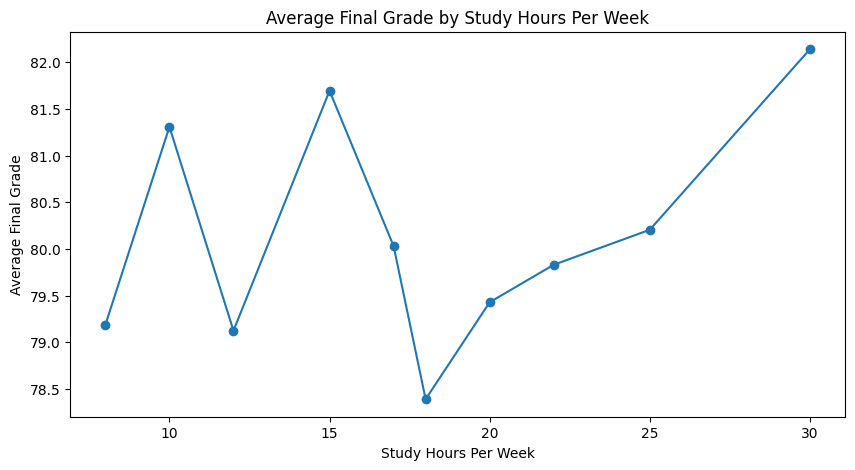

In [48]:
# Task 5: Matplotlib Visualization
# Line Chart
# Task 5.1: Line Chart

line = (
    df.groupby("StudyHoursPerWeek")["FinalGrade"]
    .mean()
    .reset_index()
    .sort_values("StudyHoursPerWeek")
)

plt.figure(figsize=(10, 5))

plt.plot(
    line["StudyHoursPerWeek"],
    line["FinalGrade"],
    marker="o"
)

plt.title("Average Final Grade by Study Hours Per Week")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Average Final Grade")

plt.show()

# Explanation:
The line chart shows the average FinalGrade for different StudyHoursPerWeek values. The average final grade fluctuates across the study-hour levels, indicating that there is no clear increasing or decreasing trend between weekly study hours and average final grade in this dataset.

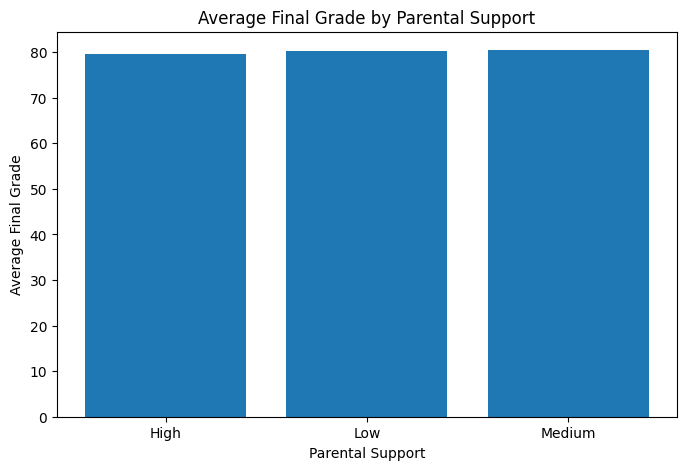

In [44]:
# Bar chart

bar = df.groupby("ParentalSupport")["FinalGrade"].mean()

plt.figure(figsize=(8, 5))

plt.bar(bar.index, bar.values)

plt.title("Average Final Grade by Parental Support")
plt.xlabel("Parental Support")
plt.ylabel("Average Final Grade")

plt.show()

# Explanation:
The bar chart compares average student final grades across different levels of parental support. It allows differences between the groups to be compared easily.

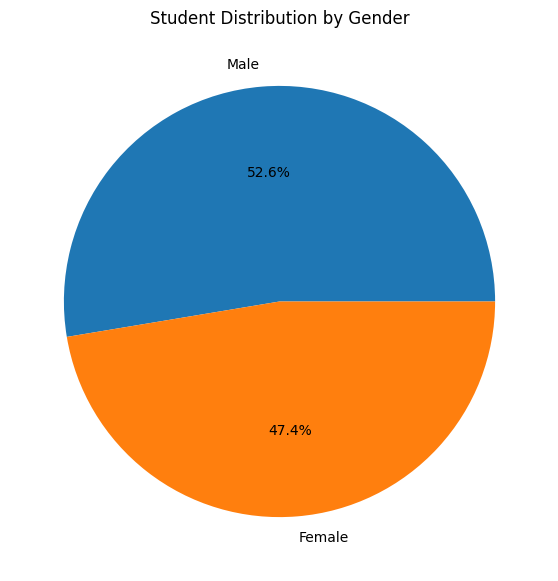

In [45]:
# pie chart

gender_counts = df["Gender"].dropna().value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%"
)

plt.title("Student Distribution by Gender")

plt.show()

# Explanation:
The pie chart shows the proportion of male and female students in the dataset, allowing the composition of the student population to be viewed as percentages.

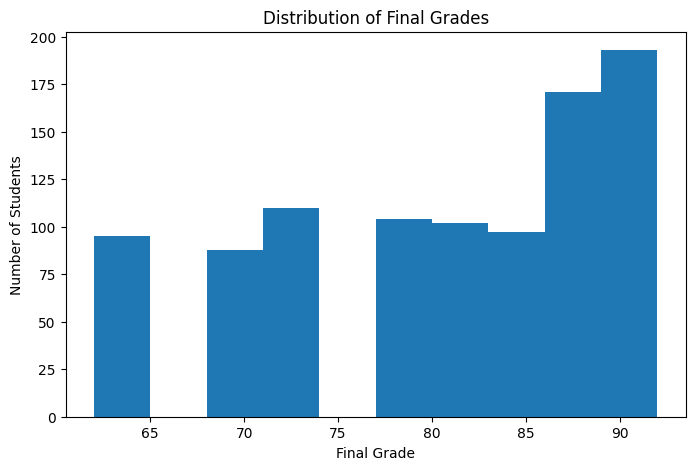

In [46]:
# Histogram

plt.figure(figsize=(8, 5))

plt.hist(
    df["FinalGrade"].dropna(),
    bins=10
)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

# Explanation:
The histogram shows the distribution of final grades and indicates the ranges in which student grades are concentrated.

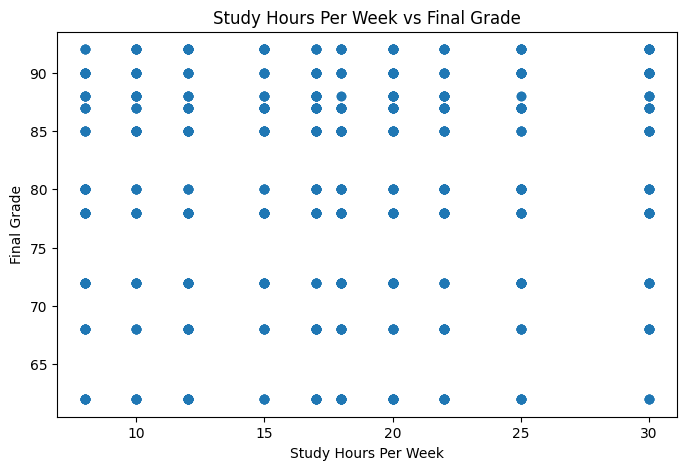

In [47]:
# Scatter plot

scatter_data = df[["StudyHoursPerWeek", "FinalGrade"]].dropna()

plt.figure(figsize=(8, 5))

plt.scatter(
    scatter_data["StudyHoursPerWeek"],
    scatter_data["FinalGrade"]
)

plt.title("Study Hours Per Week vs Final Grade")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Final Grade")

plt.show()

# Explanation:
The scatter plot displays the relationship between weekly study hours and final grades. The points are widely dispersed, which is consistent with the very weak correlation calculated in Task 3.

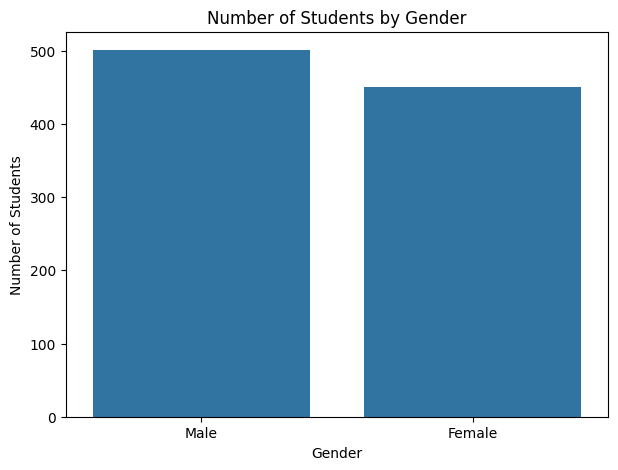

In [49]:
# Task 6: Seaborn Visualization
# Count plot

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Number of Students by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")

plt.show()

#Explanation:

The count plot shows the number of students in each gender category and provides a simple comparison of the dataset's gender distribution.

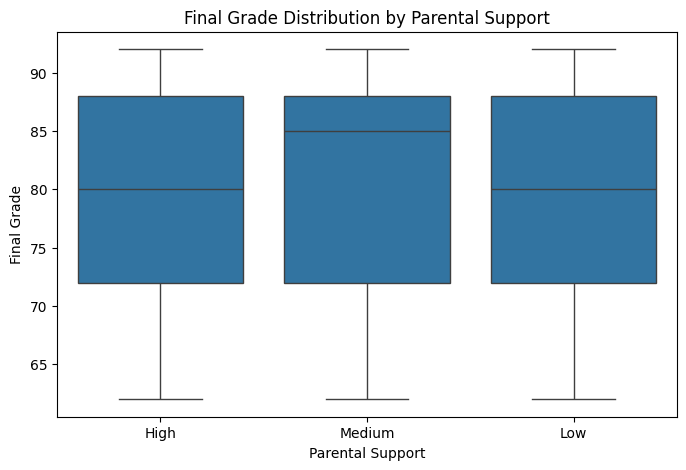

In [50]:
# Box plot

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="ParentalSupport",
    y="FinalGrade"
)

plt.title("Final Grade Distribution by Parental Support")
plt.xlabel("Parental Support")
plt.ylabel("Final Grade")

plt.show()

# Explanation:

The box plot compares the distribution of final grades across different levels of parental support. It shows the median, spread and potential extreme observations for each group.

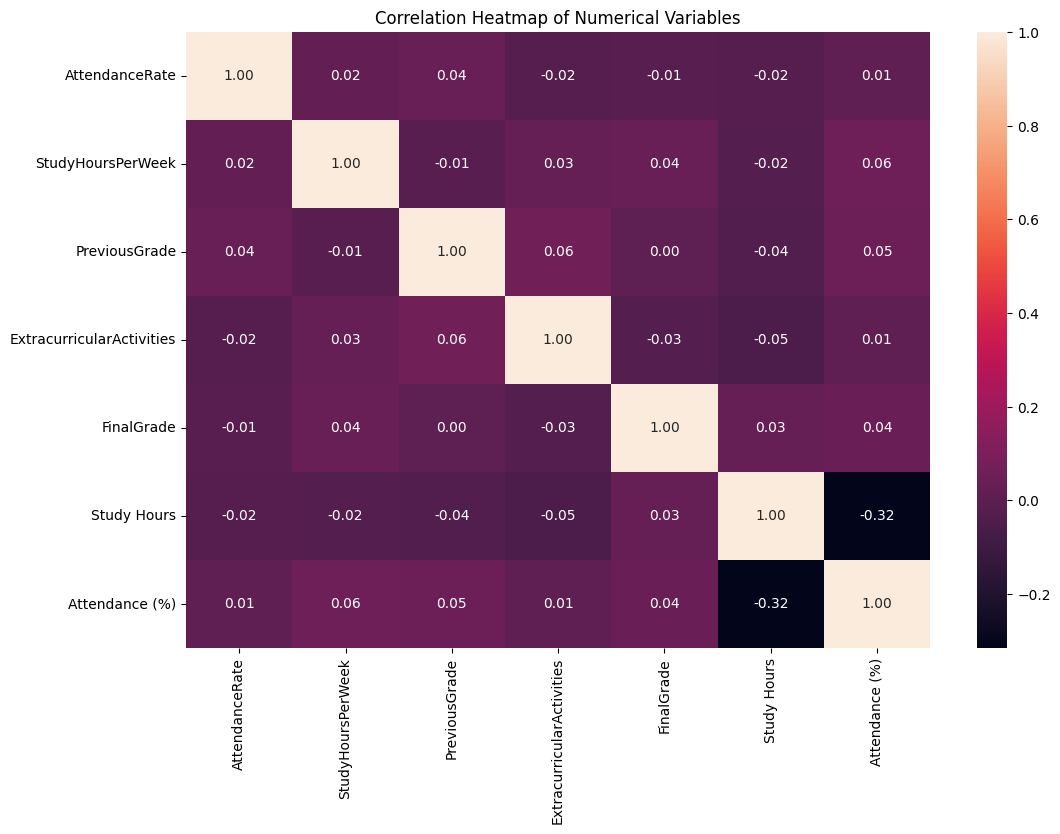

In [55]:
# heatmap

# Task 6.3: Seaborn Heatmap

heatmap_data = df[
    [
        "AttendanceRate",
        "StudyHoursPerWeek",
        "PreviousGrade",
        "ExtracurricularActivities",
        "FinalGrade",
        "Study Hours",
        "Attendance (%)"
    ]
]

correlation_matrix = heatmap_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.show()

# Explanation:

The correlation heatmap displays the relationships between the numerical variables in the dataset. Values closer to 1 indicate a positive relationship, values closer to -1 indicate a negative relationship, and values near 0 indicate a weak relationship.

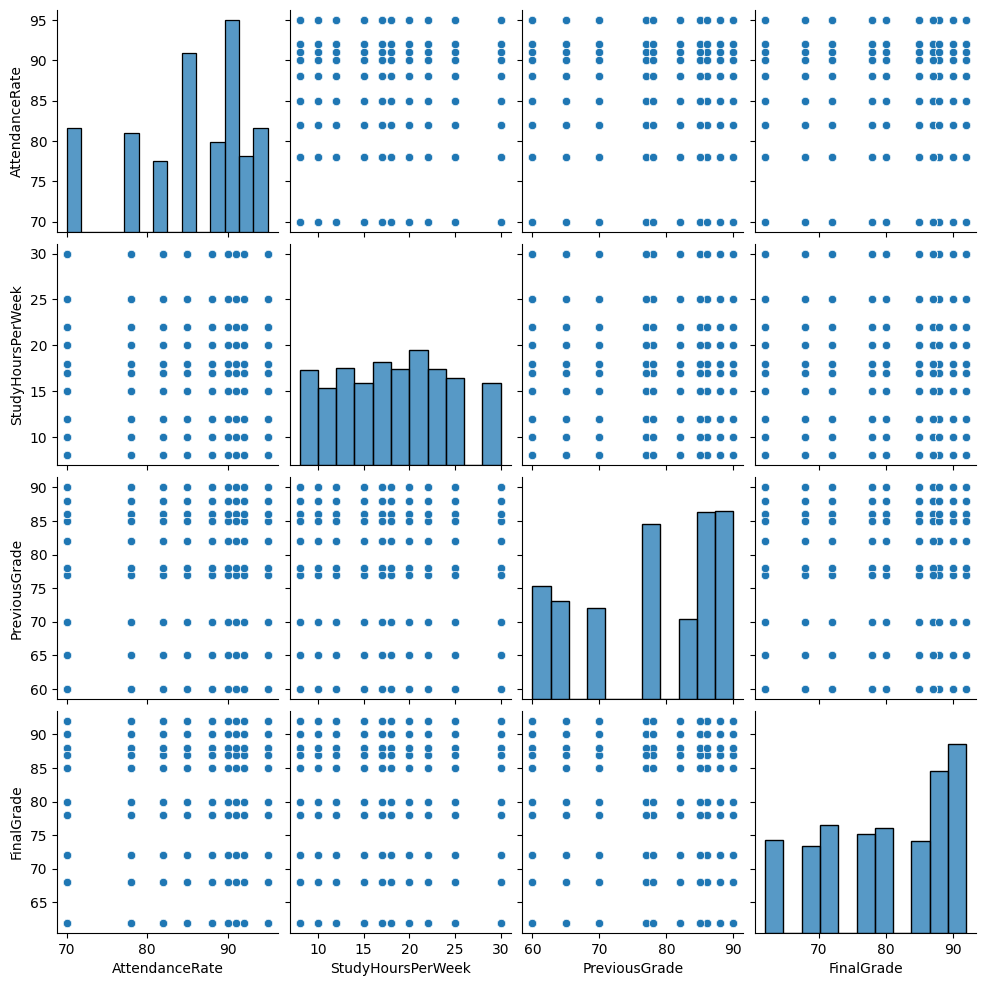

In [54]:
# Pair plot

pair_data = df[
    [
        "AttendanceRate",
        "StudyHoursPerWeek",
        "PreviousGrade",
        "FinalGrade"
    ]
].dropna()

sns.pairplot(pair_data)

plt.show()

# Explanation:

The pair plot provides a visual comparison of relationships between multiple numerical variables. It helps identify possible trends, clusters and relationships that can be investigated further.

In [58]:
# Task 7: Exploratory Data Analysis (EDA) – Data Inspection & Cleaning

print("Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe())

Shape: (1000, 12)

Column Names:
['StudentID', 'Name', 'Gender', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'FinalGrade', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']

Data Types:
StudentID                    float64
Name                          object
Gender                        object
AttendanceRate               float64
StudyHoursPerWeek            float64
PreviousGrade                float64
ExtracurricularActivities    float64
ParentalSupport               object
FinalGrade                   float64
Study Hours                  float64
Attendance (%)               float64
Online Classes Taken          object
dtype: object

Statistical Summary:


,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
count,960.000000,960.000000,950.000000,967.000000,957.000000,960.000000,976.000000,959.000000
mean,5416.019792,85.510417,17.630526,77.598759,1.520376,80.030208,2.406967,77.248175
std,2653.748319,7.332125,6.272132,10.006640,1.046439,9.493652,1.620267,19.298148
min,1.000000,70.000000,8.000000,60.000000,0.000000,62.000000,-5.000000,50.000000
25%,3113.500000,82.000000,12.000000,70.000000,1.000000,72.000000,1.200000,63.000000
50%,5396.500000,88.000000,18.000000,78.000000,1.000000,80.000000,2.500000,76.000000
75%,7754.750000,91.000000,22.000000,86.000000,2.000000,88.000000,3.700000,89.000000
max,9998.000000,95.000000,30.000000,90.000000,3.000000,92.000000,5.000000,200.000000


In [63]:
# missing values
print("Missing Values:")
print(df.isnull().sum())

# Checking for duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
StudentID                    40
Name                         34
Gender                       48
AttendanceRate               40
StudyHoursPerWeek            50
PreviousGrade                33
ExtracurricularActivities    43
ParentalSupport              22
FinalGrade                   40
Study Hours                  24
Attendance (%)               41
Online Classes Taken         25
dtype: int64

Duplicate Rows: 0


In [64]:
# checking incorrect values
print("Invalid Study Hours:")
print(df[df["Study Hours"] < 0][["StudentID", "Name", "Study Hours"]])

Invalid Study Hours:
     StudentID             Name  Study Hours
74      1470.0   Michelle Jones         -5.0
125     3430.0     Jessica Lamb         -5.0
148     5059.0  Michaela Powell         -5.0
220     8484.0     Alicia Ortiz         -5.0
251     3527.0   Michael Foster         -5.0
321     3831.0  Jessica Jenkins         -5.0
366     4659.0       Jill Kelly         -5.0
380     6416.0  Raymond Murillo         -5.0
672     8203.0   David Martinez         -5.0
798     1378.0       Chad Colon         -5.0


In [65]:
print("Invalid Attendance Values:")
print(
    df[
        (df["Attendance (%)"] < 0) |
        (df["Attendance (%)"] > 100)
    ][["StudentID", "Name", "Attendance (%)"]]
)

Invalid Attendance Values:
     StudentID             Name  Attendance (%)
74      1470.0   Michelle Jones           200.0
125     3430.0     Jessica Lamb           200.0
148     5059.0  Michaela Powell           200.0
220     8484.0     Alicia Ortiz           200.0
251     3527.0   Michael Foster           200.0
321     3831.0  Jessica Jenkins           200.0
366     4659.0       Jill Kelly           200.0
380     6416.0  Raymond Murillo           200.0
672     8203.0   David Martinez           200.0
798     1378.0       Chad Colon           200.0


In [86]:
# Cleaning the Data

clean_df = df.copy()

# 1. Handle invalid Study Hours values
clean_df.loc[
    ~clean_df["Study Hours"].between(0, 5),
    "Study Hours"
] = np.nan

# 2. Handle invalid Attendance (%) values
clean_df.loc[
    ~clean_df["Attendance (%)"].between(0, 100),
    "Attendance (%)"
] = np.nan


# 3. Handle missing numerical values
numeric_columns = [
    "AttendanceRate",
    "StudyHoursPerWeek",
    "PreviousGrade",
    "ExtracurricularActivities",
    "FinalGrade",
    "Study Hours",
    "Attendance (%)"
]

for column in numeric_columns:
    median_value = clean_df[column].median()
    clean_df.loc[clean_df[column].isna(), column] = median_value


# 4. Handle missing categorical / Boolean values
categorical_columns = [
    "Name",
    "Gender",
    "ParentalSupport",
    "Online Classes Taken"
]

for column in categorical_columns:
    mode_value = clean_df[column].mode(dropna=True)[0]
    clean_df.loc[clean_df[column].isna(), column] = mode_value


# 5. Remove duplicate records
clean_df = clean_df.drop_duplicates()

print("Cleaning completed successfully!")

Cleaning completed successfully!


In [87]:
print("\nDataset Shape:")
print(clean_df.shape)

print("\nMissing Values:")
print(clean_df.isnull().sum())

print("\nDuplicate Rows:")
print(clean_df.duplicated().sum())


Dataset Shape:
(1000, 12)

Missing Values:
StudentID                    40
Name                          0
Gender                        0
AttendanceRate                0
StudyHoursPerWeek             0
PreviousGrade                 0
ExtracurricularActivities     0
ParentalSupport               0
FinalGrade                    0
Study Hours                   0
Attendance (%)                0
Online Classes Taken          0
dtype: int64

Duplicate Rows:
0


In [89]:
# before cleaning
df.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [88]:
# after cleaning
clean_df.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,88.0,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


# Data Cleaning:
The dataset was inspected for missing values, duplicate records and inconsistent values. Invalid Study Hours values outside the expected 0–5 range and Attendance (%) values outside the 0–100 range were identified and replaced with missing values. Missing numerical values were handled using the median, while missing categorical values were filled using the mode. Duplicate records were also removed. The cleaned dataset was then checked again to verify the results.

In [79]:
# Task 8: EDA – Correlation & Insights

numeric_columns = [
    "AttendanceRate",
    "StudyHoursPerWeek",
    "PreviousGrade",
    "ExtracurricularActivities",
    "FinalGrade",
    "Study Hours",
    "Attendance (%)"
]

correlation_matrix = clean_df[numeric_columns].corr()

display(correlation_matrix)

,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
AttendanceRate,1.000000,0.013851,0.034594,-0.017937,-0.011115,-0.032583,0.011297
StudyHoursPerWeek,0.013851,1.000000,-0.010835,0.028447,0.034574,-0.016311,0.056061
PreviousGrade,0.034594,-0.010835,1.000000,0.061506,0.003830,-0.040088,0.042437
ExtracurricularActivities,-0.017937,0.028447,0.061506,1.000000,-0.030163,-0.036202,0.003443
FinalGrade,-0.011115,0.034574,0.003830,-0.030163,1.000000,0.044165,0.039404
Study Hours,-0.032583,-0.016311,-0.040088,-0.036202,0.044165,1.000000,-0.003061
Attendance (%),0.011297,0.056061,0.042437,0.003443,0.039404,-0.003061,1.000000


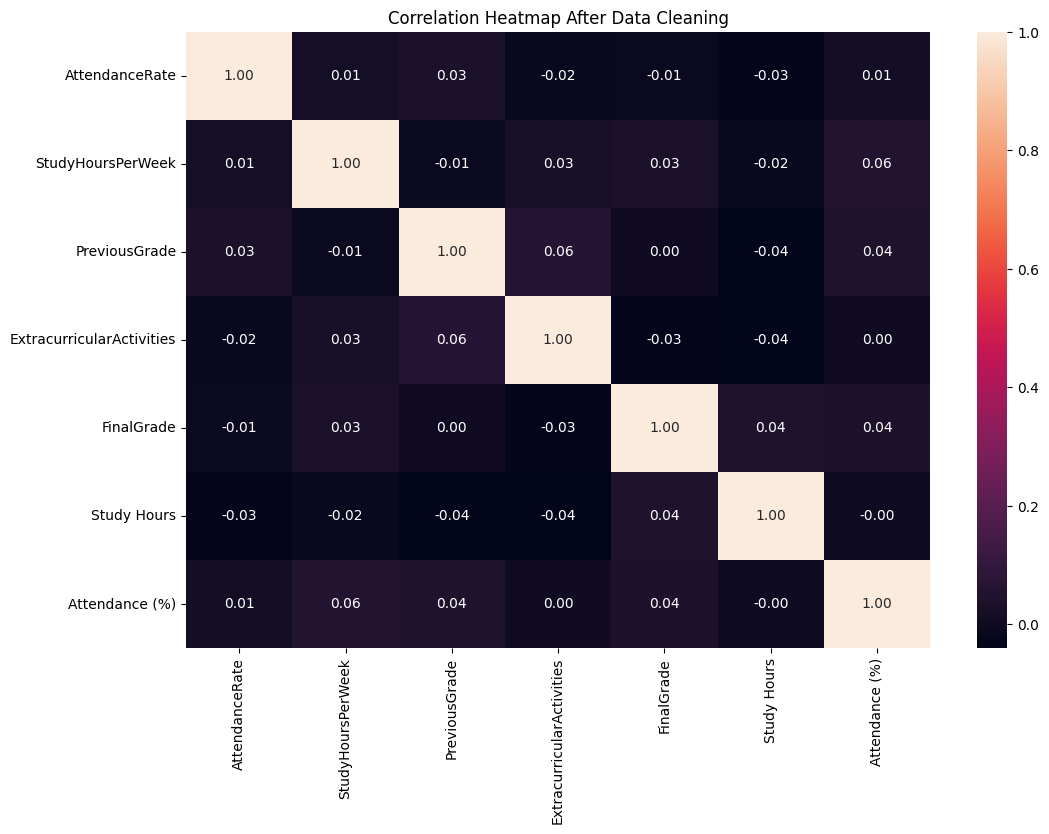

In [80]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap After Data Cleaning")

plt.show()

# Insight 1 — Study Hours
StudyHoursPerWeek and FinalGrade have a very weak positive correlation of approximately 0.035. This indicates that weekly study hours alone do not strongly explain differences in final grades in this dataset.

# Insight 2 — Previous Grade
PreviousGrade and FinalGrade have an almost zero correlation of approximately 0.004, indicating no meaningful linear relationship between these two variables in the supplied dataset.

# Insight 3 — Attendance
AttendanceRate and FinalGrade have a very weak negative correlation of approximately -0.011. Therefore, attendance rate does not show a meaningful linear relationship with final grades in this particular dataset.

# Task 9: Business Recommendations
Since this is a student-performance dataset, "business recommendations" can be interpreted as recommendations for an educational institution.

## Recommendation 1:
Use multiple student-performance factors when evaluating students. StudyHoursPerWeek has only a very weak correlation with FinalGrade (approximately 0.035), so institutions should not rely on study hours alone. Student performance should be evaluated using multiple academic and behavioral factors.

## Recommendation 2:
Implement automated data-quality validation. The dataset contained invalid Attendance (%) values of 200 and negative Study Hours values. Educational institutions should validate attendance and study-hour data before using it for analysis or decision-making.

## Recommendation 3:
Use EDA dashboards for continuous monitoring. Correlation analysis and visualizations can help institutions monitor relationships among attendance, study patterns, previous grades and final grades and identify areas requiring further investigation.